<a href="https://colab.research.google.com/github/Mashael-fs/IT326-Cardiovascular-Disease/blob/main/Reports%20Folder/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 3

## **Classification**

### importing library

In [131]:
# Import all necessary libraries
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from tabulate import tabulate


This cell imports all required libraries for data manipulation, visualization, machine learning (Decision Tree), and evaluation metrics.

### Loading the Dataset

In [132]:
# load dataset
df = pd.read_csv("Preprocessed_dataset.csv")

print("Dataset shape:", df.shape)
print(df.head())
print("\nColumns:", df.columns.tolist())

Dataset shape: (62505, 15)
   id       age  gender    height    weight     ap_hi     ap_lo  cholesterol  \
0   0 -0.447523       2  0.477189 -0.911080 -1.149069 -0.221405            1   
1   1  0.298797       1 -1.116160  0.963105  0.950343  1.081815            3   
2   2 -0.258808       1  0.078852 -0.748108  0.250539 -1.524624            3   
3   3 -0.760693       2  0.609968  0.718646  1.650146  2.385035            1   
4   8  0.984517       1 -1.780056 -0.503649 -0.449265 -0.221405            2   

   gluc  smoke  alco  active  cardio  age_years Age_Group  
0     1      0     0       1       0         50    Middle  
1     1      0     0       1       1         55       Old  
2     1      0     0       0       1         51    Middle  
3     1      0     0       1       1         48    Middle  
4     2      0     0       0       0         60       Old  

Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 

This cell loads the preprocessed cardiovascular disease dataset and displays its basic information.

### Selecting the Features and Target

In [133]:
# we should drop id, age_years, and Age_Group columns before training process
X = df.drop(
    columns=["id", "age_years", "Age_Group"],
    errors="ignore"
)

fn = df.keys().tolist()[:-1] #df columns names without last colum 'cardio'
X = df[fn] # Features names
y = df["cardio"] # Target variable

print("Feature columns:", X.columns.tolist())
print("\nClass distribution:")
print(y.value_counts().sort_index())

Feature columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years']

Class distribution:
cardio
0    31635
1    30870
Name: count, dtype: int64


This cell separates the input features from the target class. The cardio column is used as the target variable, where 0 represents the absence of cardiovascular disease and 1 represents its presence.

### Gini Index - 90% Training / 10% Testing

Accuracy: 1.0
Confusion Matrix:
[[3113    0]
 [   0 3138]]


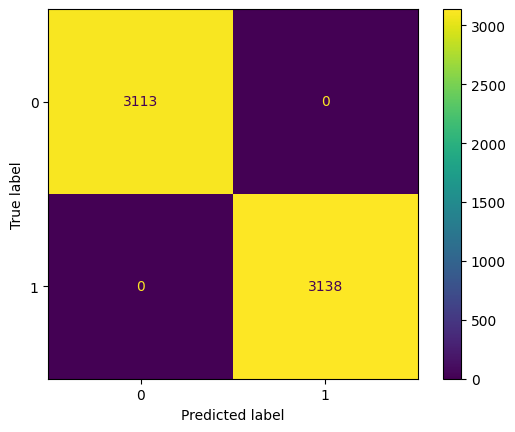

In [134]:
cn = df['cardio'].unique() #classes_names
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=1)

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

This experiment trains a Decision Tree classifier using the Gini index with 90% of the data for training and 10% for testing. The model is evaluated using a confusion matrix, accuracy.

### Gini Index - 80% Training / 20% Testing

Accuracy: 1.0
Confusion Matrix:
[[6237    0]
 [   0 6264]]


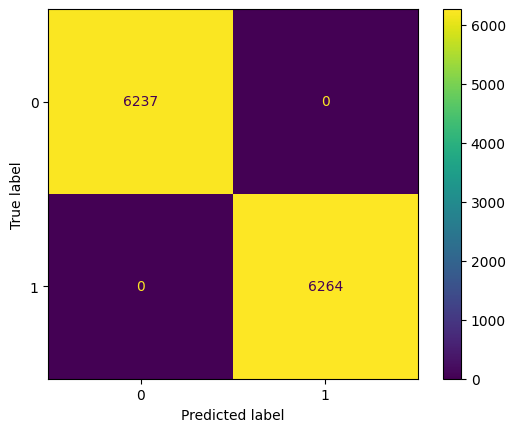

In [135]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

This experiment evaluates the Gini Decision Tree using 80% of the dataset for training and 20% for testing. The same evaluation metrics are calculated to allow comparison with the 90/10 partition.

### Gini Index - 70% Training / 30% Testing

Accuracy: 1.0
Confusion Matrix:
[[9411    0]
 [   0 9341]]


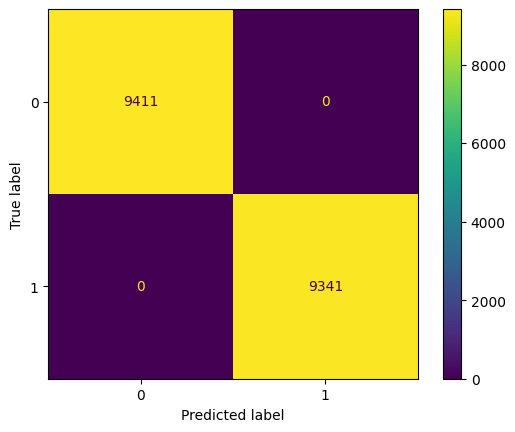

In [136]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

# Create Decision Tree classifer object
clf = DecisionTreeClassifier(random_state=1)

# Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

#compute and print the confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test, display_labels=cn)

This experiment trains and evaluates the Gini Decision Tree using 70% of the data for training and 30% for testing. Its results are compared with the other partitions to examine how the training data size affects classification performance.

### Comparison of Gini Results

In [137]:
headers = ["Data Partition","Accuracy"]

data = [
    ["90% Training / 10% Testing", "62.04%"],
    ["80% Training / 20% Testing", "62.76%"],
    ["70% Training / 30% Testing", "63.34%"]
]

print(tabulate(data, headers=headers, tablefmt="fancy_grid"))

╒════════════════════════════╤════════════╕
│ Data Partition             │ Accuracy   │
╞════════════════════════════╪════════════╡
│ 90% Training / 10% Testing │ 62.04%     │
├────────────────────────────┼────────────┤
│ 80% Training / 20% Testing │ 62.76%     │
├────────────────────────────┼────────────┤
│ 70% Training / 30% Testing │ 63.34%     │
╘════════════════════════════╧════════════╛


This section compares the accuracy of the Gini Decision Tree classifier using three different training/testing partitions: 90/10, 80/20, and 70/30. The 70/30 partition achieved the highest accuracy at 63.34%, followed by the 80/20 partition at 62.76%. The 90/10 partition achieved the lowest accuracy at 62.04%. Therefore, among the three tested partitions, the 70/30 partition provided the best classification accuracy for the Gini Decision Tree. However, the accuracy differences between the partitions were relatively small, indicating similar classification performance across the three partitions.